In [164]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

### Example 1: FTCS Method

**Partial Differential Equation (PDE):**
$$\frac{\partial u}{\partial t} = c_d \frac{\partial^2 u}{\partial x^2} + c_s u (1 - u)(u - a)$$

**Initial Condition:**
$$u(x, 0) = e^{-x^2}$$

**Boundary Conditions:**
$$u(-1, t) = u(1, t) = e^{-1}$$


### 1. Spatial grid


In [165]:

x_left = -1.0
x_right = 1.0

Nx = 80                   # number of spatial intervals

dx = (x_right - x_left) / Nx

x = np.linspace(x_left, x_right, Nx + 1)

### 2. Initial condition

In [166]:
u = np.exp(-x**2)

### 3. Boundary conditions

In [167]:


left_boundary = np.exp(-1)
right_boundary = np.exp(-1)

u[0] = left_boundary
u[-1] = right_boundary


# Save initial condition for plotting later
u_initial = u.copy()



### 4. Model parameters

In [168]:

cd = 1.0
cs = 50.0
a = 0.5

### 5. Time Settings

In [169]:
t_final = 0.1

# Choose a target FTCS diffusion ratio
r_target = 0.4

# dt calculated from:
# r = cd*dt/dx^2
dt = r_target * dx**2 / cd

# Number of time steps
Nt = int(np.ceil(t_final / dt))

# Adjust dt so final time is exactly 0.5
dt = t_final / Nt

# Actual diffusion ratio
r = cd * dt / dx**2

### 6. Grid Information

In [170]:


print("----- GRID INFORMATION -----")

print("Nx =", Nx)
print("Number of grid points =", len(x))
print("dx =", dx)

print("\n----- TIME INFORMATION -----")

print("Final time =", t_final)
print("dt =", dt)
print("Number of time steps =", Nt)
print("r =", r)

----- GRID INFORMATION -----
Nx = 80
Number of grid points = 81
dx = 0.025

----- TIME INFORMATION -----
Final time = 0.1
dt = 0.00025
Number of time steps = 400
r = 0.3999999999999999


In [171]:
# Reset to the actual initial condition
u = np.exp(-x**2)

# Reapply boundary conditions
u[0] = np.exp(-1)
u[-1] = np.exp(-1)

# Find midpoint
mid_index = Nx // 2

# Start recording from the true t = 0 solution
time_values = [0.0]
midpoint_values = [u[mid_index]]

print("Starting midpoint =", u[mid_index])

Starting midpoint = 1.0


### 7. FTCS Time stepping

In [172]:


for n in range(Nt):

    # Copy old solution
    u_new = u.copy()

    # Calculate all interior points
    for i in range(1, Nx):

        # Diffusion contribution
        diffusion = (
            r *
            (u[i+1] - 2*u[i] + u[i-1])
        )

        # Nonlinear reaction contribution
        reaction = (
            dt * cs *
            u[i] *
            (1 - u[i]) *
            (u[i] - a)
        )

        # FTCS update
        u_new[i] = (
            u[i]
            + diffusion
            + reaction
        )

    # Reapply Dirichlet boundary conditions
    u_new[0] = left_boundary
    u_new[-1] = right_boundary

    # New row becomes current row
    u = u_new

    # Current time
    current_time = (n + 1) * dt

    # Save midpoint
    time_values.append(current_time)
    midpoint_values.append(u[mid_index])

### 8. Results

In [173]:
print("\n----- FINAL RESULT -----")

print("Final time =", t_final)
print("u(0,t_final) =", u[mid_index])

print("Left boundary =", u[0])
print("Right boundary =", u[-1])


----- FINAL RESULT -----
Final time = 0.1
u(0,t_final) = 0.9651816932274999
Left boundary = 0.36787944117144233
Right boundary = 0.36787944117144233


### 9. Plot u(0,t)

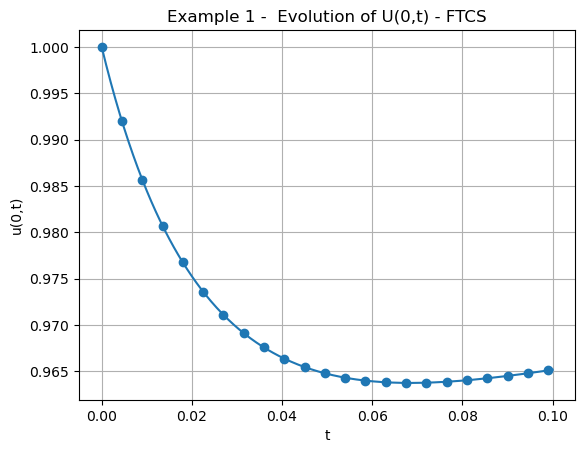

In [174]:

plt.figure()

plt.plot(
    time_values,
    midpoint_values, marker="o",markevery=18
)

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 1 -  Evolution of U(0,t) - FTCS")
plt.grid()

plt.show()

In [175]:
print(
    "Symmetry error =",
    np.max(np.abs(u - u[::-1]))
)

Symmetry error = 1.1102230246251565e-16


In [176]:
print("Minimum u =", np.min(u))
print("Maximum u =", np.max(u))
print("Contains NaN =", np.isnan(u).any())
print("Contains infinity =", np.isinf(u).any())

Minimum u = 0.36787944117144233
Maximum u = 0.9651816932274999
Contains NaN = False
Contains infinity = False


### 10. Since we are not using Mathmatica NDSolve for reference Solution, we used Python's scipy.integrate.solve_ivp for reference solution

In [177]:
def reference_solution(
    Nx_ref=800,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5
):

    # Spatial grid
    x = np.linspace(-1.0, 1.0, Nx_ref + 1)

    dx = x[1] - x[0]

    boundary = np.exp(-1)

    # Initial condition
    u0 = np.exp(-x**2)

    # We only integrate the interior points
    u0_interior = u0[1:-1]


    def rhs(t, u_interior):

        # Reconstruct complete solution
        u = np.empty(Nx_ref + 1)

        u[0] = boundary
        u[-1] = boundary

        u[1:-1] = u_interior

        # Second derivative
        u_xx = (
            u[2:]
            - 2*u[1:-1]
            + u[:-2]
        ) / dx**2

        # Reaction
        reaction = (
            cs
            * u[1:-1]
            * (1 - u[1:-1])
            * (u[1:-1] - a)
        )

        return (
            cd * u_xx
            + reaction
        )


    solution = solve_ivp(
        rhs,
        [0, t_final],
        u0_interior,
        method="BDF",
        rtol=1e-9,
        atol=1e-11
    )


    # Final complete solution
    u_final = np.empty(Nx_ref + 1)

    u_final[0] = boundary
    u_final[-1] = boundary

    u_final[1:-1] = solution.y[:, -1]

    return x, u_final

In [178]:
def ftcs_final(
    Nx,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    r_target=0.4
):

    x = np.linspace(-1.0, 1.0, Nx + 1)

    dx = x[1] - x[0]

    u = np.exp(-x**2)

    boundary = np.exp(-1)

    u[0] = boundary
    u[-1] = boundary

    # Stable timestep
    dt = r_target * dx**2 / cd

    Nt = int(np.ceil(t_final / dt))

    dt = t_final / Nt

    r = cd * dt / dx**2


    for n in range(Nt):

        u_new = u.copy()

        for i in range(1, Nx):

            diffusion = (
                r
                * (
                    u[i+1]
                    - 2*u[i]
                    + u[i-1]
                )
            )

            reaction = (
                dt
                * cs
                * u[i]
                * (1-u[i])
                * (u[i]-a)
            )

            u_new[i] = (
                u[i]
                + diffusion
                + reaction
            )

        u_new[0] = boundary
        u_new[-1] = boundary

        u = u_new

    return x, u

In [179]:
x_ref, u_ref = reference_solution()

In [180]:
Nx_values = [5, 10, 15, 20, 25, 30]

print("\nNx        Maximum absolute error")
print("--------------------------------")


for Nx in Nx_values:

    # FTCS solution
    x_ftcs, u_ftcs = ftcs_final(Nx)

    # Interpolate fine reference solution
    # onto the FTCS grid
    u_reference_at_ftcs_points = np.interp(
        x_ftcs,
        x_ref,
        u_ref
    )

    # Maximum absolute error
    error = np.max(
        np.abs(
            u_ftcs
            - u_reference_at_ftcs_points
        )
    )

    print(
        f"{Nx:<10} {error:.10e}"
    )


Nx        Maximum absolute error
--------------------------------
5          3.5162157137e-02
10         1.1181001737e-02
15         5.1366691550e-03
20         2.8565746151e-03
25         1.7985468662e-03
30         1.2319635506e-03


## Discussion of Example 1 Using the FTCS Method


The aim was to solve this problem using the FTCS finite-difference method and study how the numerical solution behaves as the grid is refined.


### Choice of the Model Parameters

One difficulty when reproducing Example 1 was the choice of the constants

$$
c_d,\qquad c_s,\qquad a.
$$

The paper defines these constants in the nonlinear reaction-diffusion model, but their numerical values are not clearly stated for Example 1.

For this reason, the first FTCS implementation used the temporary values

$$
c_d=1,\qquad c_s=1,\qquad a=0.5.
$$

The numerical solution was stable, but the midpoint value at $t=0.1$ was approximately

$$
u(0,0.1)\approx0.848.
$$

This was lower than the behaviour shown by the $\alpha=1$ , where the midpoint remains much closer to $1$.

Therefore, a small parameter sensitivity study was performed instead of assuming that the first parameter values were correct.


### Effect of $c_d$

The parameter $c_d$ controls the diffusion term

$$
c_d u_{xx}.
$$

Diffusion smooths the solution. A larger value of $c_d$ causes the initial peak at $x=0$ to decrease more quickly.

When $c_d$ was reduced while keeping

$$
c_s=1,\qquad a=0.5,
$$

the midpoint stayed closer to $1$.

For example,

$$
c_d=0.2
$$

gave

$$
u(0,0.1)\approx0.964.
$$

This showed that the value of the diffusion coefficient has a strong effect on how quickly the solution decreases.


### Effect of $c_s$

The coefficient $c_s$ controls the strength of the nonlinear reaction term

$$
c_su(1-u)(u-a).
$$

When $c_s$ becomes larger, the nonlinear reaction has a stronger effect on the solution.

For $a=0.5$, if

$$
u>0.5,
$$

then

$$
u-a>0.
$$

Therefore, the nonlinear reaction term is positive and tends to push the solution upward towards $u=1$.

This means that the reaction term can oppose the downward smoothing effect caused by diffusion.

The following parameter combinations were tested:

| $c_d$ | $c_s$ | $a$ | $u(0,0.1)$ |
|---:|---:|---:|---:|
| 1.0 | 1.0 | 0.5 | 0.8481 |
| 0.5 | 1.0 | 0.5 | 0.9157 |
| 0.2 | 1.0 | 0.5 | 0.9638 |
| 1.0 | 10.0 | 0.5 | 0.8794 |
| 1.0 | 50.0 | 0.5 | 0.9652 |

Two parameter sets gave midpoint values close to the behaviour shown in the paper:

$$
(c_d,c_s,a)=(0.2,1,0.5)
$$

and

$$
(c_d,c_s,a)=(1,50,0.5).
$$

However, matching only the value at $t=0.1$ was not enough. The full midpoint curve $u(0,t)$ was also considered.

The choice

$$
\boxed{c_d=1,\qquad c_s=50,\qquad a=0.5}
$$

produced a midpoint curve that decreased from

$$
u(0,0)=1
$$

and then became nearly constant close to

$$
u(0,t)\approx0.965.
$$

This behaviour was similar to the shape of the $\alpha=1$ curve shown in Figure 1 of the paper.

Therefore, these values were selected as **working parameter values** for the FTCS investigation.

It is important to note that these values are **not claimed to be the exact parameter values used by the authors of the paper**. They were selected from the sensitivity study because they produced behaviour that was reasonably consistent with the published $\alpha=1$ result.


### Checking the FTCS Solution

Before performing the error analysis, several checks were carried out to make sure that the FTCS implementation was working correctly.

The initial condition

$$
u(x,0)=e^{-x^2}
$$

is symmetric about $x=0$.

The boundary conditions are also symmetric because

$$
u(-1,t)=u(1,t)=e^{-1}.
$$

Therefore, the numerical solution should satisfy approximately

$$
u(-x,t)=u(x,t).
$$

The calculated symmetry error was

$$
5.55\times10^{-17}.
$$

This value is extremely close to zero and is mainly caused by normal floating-point rounding on the computer. This showed that the FTCS solution preserved the symmetry of the problem.

The solution was also checked for invalid numerical values. No `NaN` values or infinite values were found.

This gave confidence that the numerical calculation was stable for the chosen timestep.


### Grid Refinement Check

A grid refinement test was performed using

$$
N_x=10,\ 20,\ 40,\ 80,\ 160.
$$

Using the original temporary parameters, the calculated midpoint values at $t=0.1$ were

| $N_x$ | $u(0,0.1)$ |
|---:|---:|
| 10 | 0.84631 |
| 20 | 0.84761 |
| 40 | 0.84802 |
| 80 | 0.84812 |
| 160 | 0.84814 |

The values become closer to each other as $N_x$ increases.

This showed that the FTCS solution was converging as the grid was refined.

It also showed that the large difference between the first FTCS result and Figure 1 of the paper was not mainly caused by using a coarse grid. The choice of the model parameters had a much larger effect.


### Maximum Absolute Error

The next step was to study the accuracy of the FTCS method at

$$
t=0.5.
$$

The paper also reports maximum absolute errors for Example 1 at $t=0.5$.

In the paper, the numerical solution was compared with Mathematica's `NDSolve` solution.

For this FTCS investigation, a high-resolution numerical reference solution was calculated in Python using `solve_ivp` with a fine spatial grid and strict numerical tolerances.

The maximum absolute error was calculated using

$$
E_{\max}
=
\max_i
\left|
u_{\text{FTCS}}(x_i,0.5)
-
u_{\text{ref}}(x_i,0.5)
\right|.
$$

This means that the difference between the FTCS solution and the reference solution was calculated at every spatial grid point.

The largest difference was then taken as the maximum absolute error.


### Error Results

The following results were obtained:

| $N_x$ | Maximum Absolute Error |
|---:|---:|
| 5 | $3.5162\times10^{-2}$ |
| 10 | $1.1181\times10^{-2}$ |
| 15 | $5.1367\times10^{-3}$ |
| 20 | $2.8566\times10^{-3}$ |
| 25 | $1.7985\times10^{-3}$ |
| 30 | $1.2320\times10^{-3}$ |

The table shows that the error decreases as the number of spatial intervals increases.

For example,

$$
E_{10}\approx1.1181\times10^{-2}
$$

and

$$
E_{20}\approx2.8566\times10^{-3}.
$$

The ratio of these two errors is approximately

$$
\frac{E_{10}}{E_{20}}
\approx3.91.
$$

When $N_x$ is doubled from $10$ to $20$, the spatial step $\Delta x$ is approximately halved.

For a second-order spatial approximation, halving $\Delta x$ should reduce the error by approximately

$$
2^2=4.
$$

The observed reduction was approximately

$$
3.91,
$$

which is close to $4$.

This suggests that the numerical results are consistent with the expected second-order behaviour of the centred finite-difference approximation used for $u_{xx}$.


### Comparison With the Results in the Paper

The FTCS errors are larger than the errors reported in Table 1 of the original paper.

For the finer values of $N_x$, the paper reports errors of approximately

$$
1.5\times10^{-4},
$$

while the FTCS error obtained at

$$
N_x=30
$$

was approximately

$$
1.23\times10^{-3}.
$$

However, these results are not a direct one-to-one comparison.

The original paper used a hybrid method involving the Laplace transform and Chebyshev collocation. The authors compared their numerical results with Mathematica's `NDSolve`.

In this investigation, the PDE was solved using the simpler FTCS finite-difference method, and the error was calculated against a high-resolution Python reference solution.

Therefore, the aim was not to obtain exactly the same error values as the paper. Instead, the purpose was to determine whether FTCS could produce a stable and convergent solution for the classical case $\alpha=1$.


### Overall Discussion

The FTCS method was able to solve the classical version of Example 1 successfully.

The numerical solution preserved the symmetry and fixed boundary conditions of the original problem. The grid refinement test showed that the numerical solution converged as the spatial resolution was increased.

The error study also showed that the maximum absolute error decreased steadily as $N_x$ increased, with behaviour close to second-order spatial convergence.

The parameter sensitivity study showed that the constants $c_d$ and $c_s$ have a strong effect on the solution. The diffusion coefficient $c_d$ controls how quickly the solution is smoothed, while $c_s$ controls the strength of the nonlinear reaction term.

For the remainder of this investigation, the working values

$$
\boxed{c_d=1,\qquad c_s=50,\qquad a=0.5}
$$

were used because they produced midpoint behaviour similar to the $\alpha=1$ result shown in the paper.

These values should be treated as working values obtained from the sensitivity study and not as confirmed parameter values from the original paper.